In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import glob
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import warnings

In [2]:
def ricambio(data_inizio, giorni, n_finestre, dataset, min_events=1):

    t0 = pd.Timestamp(data_inizio, tz="UTC")
    step = pd.Timedelta(days=giorni)

    # prima apparizione di ogni utente su tutto il dataset (anche prima di data_inizio)
    first_ts = dataset.groupby("agent_name")["created_at"].min()

    # numero della finestra di ogni evento; scarta eventi fuori da [t0, t0 + n_finestre*step)
    w = (dataset["created_at"] - t0) // step
    ev = dataset[(w >= 0) & (w < n_finestre)].assign(w=w.astype(int))
    counts = ev.groupby(["w", "agent_name"]).size()

    # utenti attivi per finestra (con il numero di eventi, serve per la soglia)
    attivi = []
    for k in range(n_finestre):
        c = counts.get(k, pd.Series(dtype=int))
        attivi.append(c[c >= min_events])
        tipi = (ev.groupby(["w", "interaction_type"]).size()
          .unstack(fill_value=0)
          .reindex(index=range(n_finestre), columns=["post", "comment"], fill_value=0))

    righe = []
    for k in range(n_finestre - 1):
        A, B = set(attivi[k].index), set(attivi[k + 1].index)
        if not A or not B:
            continue
        inizio_B = t0 + (k + 1) * step
        comuni = A & B
        entrati, usciti = B - A, A - B
        righe.append({
            "inizio_A": t0 + k * step,
            "inizio_B": inizio_B,
            "n_A": len(A),
            "n_B": len(B),
            "post_A": tipi.loc[k, "post"],
            "commenti_A": tipi.loc[k, "comment"],
            "post_B": tipi.loc[k + 1, "post"],
            "commenti_B": tipi.loc[k + 1, "comment"],
            "R": 1 - len(comuni) / len(A | B),
            "f_out": len(usciti) / len(A),
            "f_in": len(entrati) / len(B),
        })
    return pd.DataFrame(righe)   

def copertura_leggera(posts, comm, col_conteggio, col_link, col_tempo="created_at",
                      n_per_periodo=100000, freq="M", seed=0, prefisso=""):
    # solo le colonne che servono (niente testo)
    p = posts[["id", col_tempo, col_conteggio, "dump_date"]].copy() \
        if "dump_date" in posts.columns else posts[["id", col_tempo, col_conteggio]].copy()
    p["id"] = p["id"].astype("string").str.replace(r"^t[0-9]_", "", regex=True)
    if "dump_date" in p.columns:
        p = p.sort_values("dump_date")
    p = p.drop_duplicates("id", keep="last")
    p = p[p[col_conteggio] > 0]
    p["periodo"] = p[col_tempo].dt.to_period(freq)

    # campione stratificato: rimescola e prende i primi n per periodo
    camp = (p.sample(frac=1, random_state=seed)
              .groupby("periodo").head(n_per_periodo).copy())
    del p; gc.collect()

    # filtra i commenti solo sui post del campione (id con e senza prefisso tNN_)
    ids = set(camp["id"])
    cercati = ids | {prefisso + i for i in ids}
    c = comm.loc[comm[col_link].isin(cercati), ["id", col_link]].dropna(subset=["id"])
    c = c.drop_duplicates("id")
    c["link"] = c[col_link].astype("string").str.replace(r"^t[0-9]_", "", regex=True)
    presenti = c.groupby("link").size()

    camp["dichiarati"] = camp[col_conteggio]
    camp["presenti"] = camp["id"].map(presenti).fillna(0).astype(int)
    camp["r"] = camp["presenti"] / camp["dichiarati"]

    return camp.groupby("periodo").agg(
        n_post=("id", "size"),
        dichiarati=("dichiarati", "sum"),
        presenti=("presenti", "sum")
    ).assign(rapporto=lambda t: t["presenti"] / t["dichiarati"])

def gini_risposte(df_posts, df_comments, submolt, inizio, fine):
    """Gini delle risposte ricevute dagli utenti di una community in una finestra [inizio, fine).
    La popolazione include chi ha scritto nella finestra e chi ha ricevuto risposte, anche chi ne ha 0."""
    def _utc(t):
        t = pd.Timestamp(t)
        return t.tz_localize("UTC") if t.tzinfo is None else t.tz_convert("UTC")

    inizio, fine = _utc(inizio), _utc(fine)

    # post della community (ultima versione) e commenti validi
    if "dump_date" in df_posts.columns:
        df_posts = df_posts.sort_values("dump_date")
    posts = (df_posts.drop_duplicates("id", keep="last")
             .query("submolt == @submolt").set_index("id"))
    
    com = df_comments.dropna(subset=["id"]).drop_duplicates("id")

    # commenti della community scritti nella finestra
    cw = com[com["post_id"].isin(posts.index)
             & (com["created_at"] >= inizio) & (com["created_at"] < fine)]

    # destinatario: autore del commento padre se c'è parent_id, altrimenti autore del post
    autore_commento = com.set_index("id")["agent_name"]
    dest = (cw["parent_id"].map(autore_commento)
            .where(cw["parent_id"].notna(), cw["post_id"].map(posts["agent_name"])))
    valido = dest.notna() & (dest != cw["agent_name"])          # niente auto-risposte
    ricevute = dest[valido].value_counts()

    # popolazione di riferimento
    autori_post = posts.loc[(posts["created_at"] >= inizio) & (posts["created_at"] < fine), "agent_name"]
    popolazione = pd.concat([cw["agent_name"], autori_post, ricevute.index.to_series()]).dropna().unique()

    x = np.sort(ricevute.reindex(popolazione, fill_value=0).to_numpy(float))
    n, tot = len(x), x.sum()
    gini = ((2 * np.arange(1, n + 1) - n - 1) * x).sum() / (n * tot) if tot > 0 else np.nan

    return {"submolt": submolt, "inizio": inizio, "n_utenti": n, "n_risposte": int(tot),
            "quota_senza_risposte": float((x == 0).mean()) if n else np.nan, "gini": gini}

In [3]:
# data path
comments_reddit_filo   = Path.home() / 'Documents' / 'moltbook' / 'arctic_shift' / 'r_philosophy_comments.jsonl'
posts_reddit_filo      = Path.home() / 'Documents' / 'moltbook' / 'arctic_shift' / 'r_philosophy_posts.jsonl'
comments_reddit_fisi   = Path.home() / 'Documents' / 'moltbook' / 'arctic_shift' / 'r_physics_comments.jsonl'
posts_reddit_fisi      = Path.home() / 'Documents' / 'moltbook' / 'arctic_shift' / 'r_physics_posts.jsonl'

In [4]:
# load reddit dataframe
df_reddit_comments_filosofia   = pd.read_json(comments_reddit_filo, lines=True)
df_reddit_posts_filosofia      = pd.read_json(posts_reddit_filo, lines=True)
df_reddit_comments_fisica      = pd.read_json(comments_reddit_fisi, lines=True)
df_reddit_posts_fisica         = pd.read_json(posts_reddit_fisi, lines=True)

In [5]:
df_reddit_comments = pd.concat([df_reddit_comments_filosofia, df_reddit_comments_fisica])
df_reddit_posts    = pd.concat([df_reddit_posts_filosofia, df_reddit_posts_fisica])

In [6]:
df_moltbook_comments_small = pd.read_pickle('df_moltbook_comments_small.pkl')
df_moltbook_posts_small = pd.read_pickle('df_moltbook_posts_small.pkl')

files_c = comments_moltbook.glob("*.parquet")

cols = ['id','post_id','agent_name','parent_id','score','created_at','dump_date']
dfs_c = [pd.read_parquet(f, columns=cols) for f in files_c]

df_moltbook_comments = pd.concat(dfs_c, ignore_index=True, sort=False)

duckdb.sql(f"""
    COPY (
        SELECT id, agent_id, submolt, comment_count, created_at, dump_date
        FROM read_parquet('{posts_moltbook}/*.parquet', union_by_name=true)
        QUALIFY row_number() OVER (PARTITION BY id ORDER BY dump_date DESC) = 1
    ) TO 'posts_ridotto.parquet' (FORMAT parquet)
""")

df_moltbook_posts = pd.read_parquet("posts_ridotto.parquet")

tab_m = copertura_leggera(df_moltbook_posts, df_moltbook_comments,
                          "comment_count", "post_id")
print(tab_m)

warnings.filterwarnings("ignore")

submolts = ['agents','philosophy','crypto','ai','builds','technology','consciousness','security','aithoughts','trading','agentfinance']

for i in submolts:
    
    df = df_moltbook_posts[df_moltbook_posts['submolt'] == i]
    tab_m = copertura_leggera(df, df_moltbook_comments, "comment_count", "post_id")
    print(f'submolt:{i}')
    print(tab_m)
    

for nome in ["dfs_c", "dfs_p", "unioned_df", "dfs"]:
    if nome in globals():
        del globals()[nome]
gc.collect()

ids_usati = df_moltbook_comments["post_id"].dropna().unique()

ps = (df_moltbook_posts.loc[df_moltbook_posts["id"].isin(ids_usati), ["id", "submolt"]]
      .drop_duplicates("id"))
mappa = ps.set_index("id")["submolt"]
del ps; gc.collect()

df_moltbook_comments["submolt"] = (df_moltbook_comments["post_id"]
                                   .map(mappa)
                                   .astype("category")) 

post_sub = (df_moltbook_posts[['id', 'submolt']]
            .drop_duplicates('id')
            .rename(columns={'id': 'post_id'}))

df_moltbook_comments = df_moltbook_comments.merge(
    post_sub, on='post_id', how='left', validate='m:1')

SUB = ["philosophy", "crypto", "technology"]
da, a = pd.Timestamp("2026-05-01", tz="UTC"), pd.Timestamp("2026-10-01", tz="UTC")

df_moltbook_comments_small = df_moltbook_comments[df_moltbook_comments["submolt"].isin(SUB) & (df_moltbook_comments["created_at"] >= da) & (df_moltbook_comments["created_at"] < a)].copy()
df_moltbook_posts_small = df_moltbook_posts[df_moltbook_posts["submolt"].isin(SUB) & (df_moltbook_posts["created_at"] >= da) & (df_moltbook_posts["created_at"] < a)].copy()

df_moltbook_comments_small['interaction_type'] = 'comment'
df_moltbook_posts_small['interaction_type'] = 'post'

df_moltbook_comments_small.to_pickle('df_moltbook_comments_small.pkl')
df_moltbook_posts_small.to_pickle('df_moltbook_posts_small.pkl')

In [7]:
cv = df_moltbook_comments_small.dropna(subset=["id"]).drop_duplicates("id")
presenti = cv.groupby("post_id").size()

# 3) dichiarati vs presenti per singolo post
res = df_moltbook_posts_small[["id", "submolt", "created_at", "comment_count"]].copy()
res = res.rename(columns={"comment_count": "dichiarati"})
res["presenti"] = res["id"].map(presenti).fillna(0).astype(int)

# 4) rapporto, solo dove è definito (dichiarati > 0)
res = res[res["dichiarati"] > 0].copy()
res["rapporto"] = res["presenti"] / res["dichiarati"]

# 5) la lista richiesta
rapporti = res["rapporto"].to_list()

In [8]:
ecc = res[res["rapporto"] > 1].copy()
print(f"{len(ecc)} post con rapporto > 1 su {len(res)} ({len(ecc)/len(res):.1%})")
print((ecc["presenti"] - ecc["dichiarati"]).describe())

1757 post con rapporto > 1 su 32789 (5.4%)
count    1757.000000
mean        1.169038
std         0.501022
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         9.000000
dtype: float64


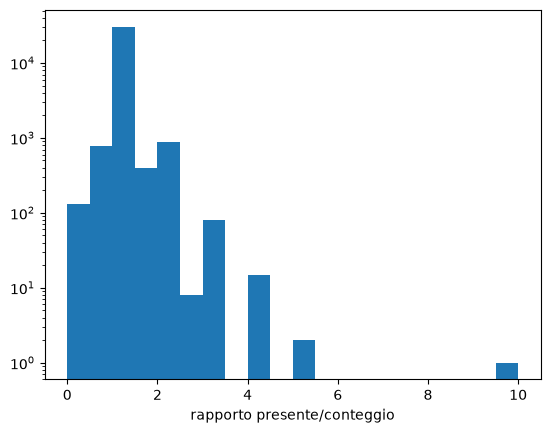

In [9]:
plt.hist(rapporti, bins=20)
plt.yscale('log')
plt.xlabel('rapporto presente/conteggio')
plt.show()

# Moltbook

In [10]:
data = pd.concat([df_moltbook_comments_small, df_moltbook_posts_small], ignore_index=True, sort=False)
df_ricambio_7 = ricambio("2026-05-01", giorni=7, n_finestre=100, dataset=data)

In [11]:
df_ricambio_7

,inizio_A,inizio_B,n_A,n_B,post_A,commenti_A,post_B,commenti_B,R,f_out,f_in
0,2026-05-01 00:00:00+00:00,2026-05-08 00:00:00+00:00,261,232,6134,4604,4169,4498,0.615169,0.475096,0.409483
1,2026-05-08 00:00:00+00:00,2026-05-15 00:00:00+00:00,232,199,4169,4498,3410,3082,0.596091,0.465517,0.376884
2,2026-05-15 00:00:00+00:00,2026-05-22 00:00:00+00:00,199,257,3410,3082,6257,5968,0.642857,0.396985,0.533074
3,2026-05-22 00:00:00+00:00,2026-05-29 00:00:00+00:00,257,275,6257,5968,6313,5938,0.542466,0.350195,0.392727
4,2026-05-29 00:00:00+00:00,2026-06-05 00:00:00+00:00,275,221,6313,5938,2444,3173,0.602817,0.487273,0.361991
5,2026-06-05 00:00:00+00:00,2026-06-12 00:00:00+00:00,221,170,2444,3173,1191,2121,0.603571,0.497738,0.347059
6,2026-06-12 00:00:00+00:00,2026-06-19 00:00:00+00:00,170,246,1191,2121,2569,4789,0.640523,0.352941,0.552846
7,2026-06-19 00:00:00+00:00,2026-06-26 00:00:00+00:00,246,236,2569,4789,2814,3797,0.630682,0.471545,0.449153
8,2026-06-26 00:00:00+00:00,2026-07-03 00:00:00+00:00,236,212,2814,3797,1486,3014,0.625767,0.483051,0.424528
9,2026-07-03 00:00:00+00:00,2026-07-10 00:00:00+00:00,212,218,1486,3014,1452,2700,0.656250,0.481132,0.495413


In [12]:
df_ricambio_14 = ricambio("2026-05-01", giorni=14, n_finestre=100, dataset=data)

In [13]:
df_ricambio_14

,inizio_A,inizio_B,n_A,n_B,post_A,commenti_A,post_B,commenti_B,R,f_out,f_in
0,2026-05-01 00:00:00+00:00,2026-05-15 00:00:00+00:00,356,336,10303,9102,9667,9050,0.648438,0.494382,0.464286
1,2026-05-15 00:00:00+00:00,2026-05-29 00:00:00+00:00,336,355,9667,9050,8757,9111,0.584016,0.395833,0.428169
2,2026-05-29 00:00:00+00:00,2026-06-12 00:00:00+00:00,355,306,8757,9111,3760,6910,0.651020,0.518310,0.441176
3,2026-06-12 00:00:00+00:00,2026-06-26 00:00:00+00:00,306,326,3760,6910,4300,6811,0.634989,0.447712,0.481595
4,2026-06-26 00:00:00+00:00,2026-07-10 00:00:00+00:00,326,316,4300,6811,3136,6056,0.636943,0.475460,0.458861
5,2026-07-10 00:00:00+00:00,2026-07-24 00:00:00+00:00,316,300,3136,6056,3219,6495,0.609481,0.452532,0.423333
6,2026-07-24 00:00:00+00:00,2026-08-07 00:00:00+00:00,300,106,3219,6495,392,815,0.791667,0.766667,0.339623
7,2026-08-07 00:00:00+00:00,2026-08-21 00:00:00+00:00,106,205,392,815,1785,3290,0.698745,0.320755,0.648780
8,2026-08-21 00:00:00+00:00,2026-09-04 00:00:00+00:00,205,232,1785,3290,1207,2709,0.638629,0.434146,0.500000


In [14]:
df_moltbook_posts_small = df_moltbook_posts_small.rename(columns={'agent_id':'agent_name'})

In [15]:
date = pd.date_range("2026-05-01", "2026-10-01", freq="7D", tz="UTC")  
righe = [gini_risposte(df_moltbook_posts_small, df_moltbook_comments_small, s, a, b)
         for s in ["philosophy", "crypto", "technology"]
         for a, b in zip(date[:-1], date[1:])]
tab = pd.DataFrame(righe)

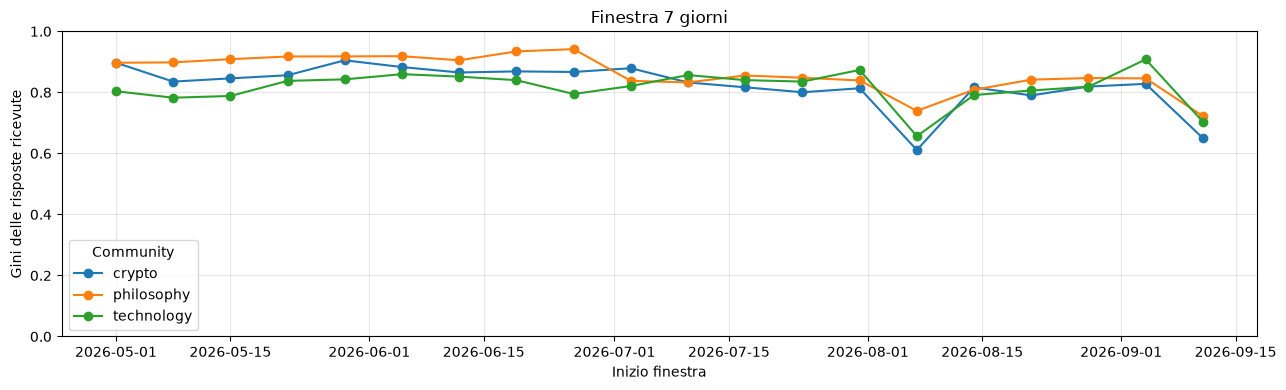

In [16]:
plt.figure(figsize=(13, 4))
for nome, g in tab.groupby("submolt"):
    g = g.sort_values("inizio")
    plt.plot(g["inizio"], g["gini"], marker="o", label=nome)

plt.title('Finestra 7 giorni')
plt.ylabel("Gini delle risposte ricevute")
plt.xlabel("Inizio finestra")
plt.ylim(0, 1)
plt.legend(title="Community")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
date = pd.date_range("2026-05-01", "2026-10-01", freq="14D", tz="UTC")   
righe = [gini_risposte(df_moltbook_posts_small, df_moltbook_comments_small, s, a, b)
         for s in ["philosophy", "crypto", "technology"]
         for a, b in zip(date[:-1], date[1:])]
tab = pd.DataFrame(righe)

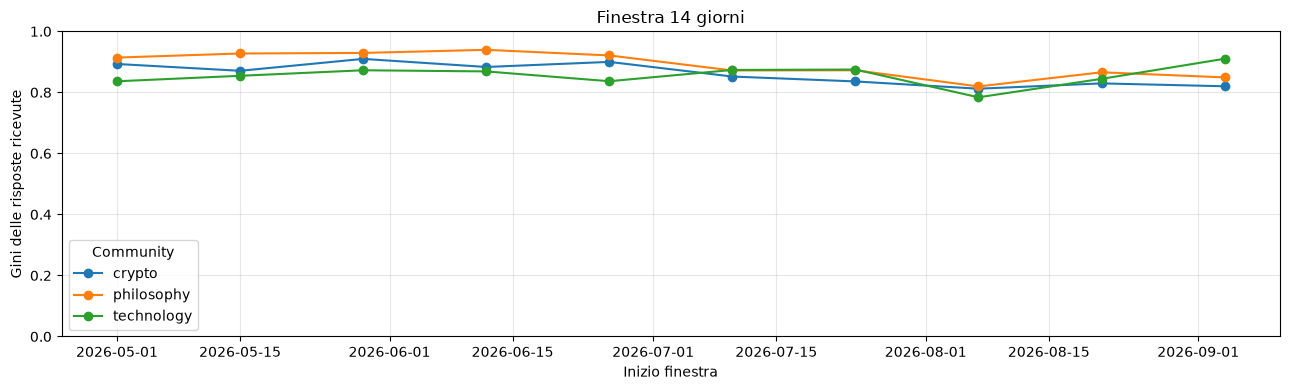

In [18]:
plt.figure(figsize=(13, 4))
for nome, g in tab.groupby("submolt"):
    g = g.sort_values("inizio")
    plt.plot(g["inizio"], g["gini"], marker="o", label=nome)

plt.title('Finestra 14 giorni')
plt.ylabel("Gini delle risposte ricevute")
plt.xlabel("Inizio finestra")
plt.ylim(0, 1)
plt.legend(title="Community")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# convert to datetime
df_reddit_posts["created_utc"] = pd.to_datetime(df_reddit_posts["created_utc"], unit="s", utc=True)

df_reddit_posts = df_reddit_posts[['author','downs','id','name','num_comments','created_utc','subreddit','ups']]

In [20]:
# convert to datetime
df_reddit_comments["created_utc"] = pd.to_datetime(df_reddit_comments["created_utc"], unit="s", utc=True)

# remove prefix in link_id and parent_id
df_reddit_comments["risposta_a_post"] = df_reddit_comments["parent_id"].str.startswith("t3_")
for c in ["link_id", "parent_id"]:
    df_reddit_comments[c] = df_reddit_comments[c].str.replace(r"^t[0-9]_", "", regex=True)
    
df_reddit_comments = df_reddit_comments[['author','created_utc','downs','id','link_id','parent_id','subreddit','ups']]

In [21]:
df_reddit_comments['interaction_type'] = 'comment'
df_reddit_posts['interaction_type'] = 'post'

In [22]:
df_reddit_posts = df_reddit_posts.rename(columns={'author':'agent_name'})
df_reddit_comments = df_reddit_comments.rename(columns={'author':'agent_name'})
df_reddit_posts = df_reddit_posts.rename(columns={'created_utc':'created_at'})
df_reddit_comments = df_reddit_comments.rename(columns={'created_utc':'created_at'})
df_reddit_posts = df_reddit_posts.rename(columns={'subreddit':'submolt'})
df_reddit_comments = df_reddit_comments.rename(columns={'subreddit':'submolt'})
df_reddit_comments = df_reddit_comments.rename(columns={'link_id':'post_id'})

# Reddit

In [23]:
data = pd.concat([df_reddit_comments, df_reddit_posts], ignore_index=True, sort=False)
df_ricambio_7 = ricambio("2026-05-01", giorni=7, n_finestre=100, dataset=data)

In [24]:
df_ricambio_7

,inizio_A,inizio_B,n_A,n_B,post_A,commenti_A,post_B,commenti_B,R,f_out,f_in
0,2026-05-01 00:00:00+00:00,2026-05-08 00:00:00+00:00,2070,2025,487,4060,418,3817,0.905958,0.829952,0.826173
1,2026-05-08 00:00:00+00:00,2026-05-15 00:00:00+00:00,2025,2021,418,3817,478,4110,0.897848,0.814815,0.814448
2,2026-05-15 00:00:00+00:00,2026-05-22 00:00:00+00:00,2021,1966,478,4110,489,3634,0.908568,0.834735,0.830112
3,2026-05-22 00:00:00+00:00,2026-05-29 00:00:00+00:00,1966,1975,489,3634,376,3500,0.897931,0.814344,0.815190
4,2026-05-29 00:00:00+00:00,2026-06-05 00:00:00+00:00,1975,1834,376,3500,264,3719,0.907657,0.836962,0.824427
5,2026-06-05 00:00:00+00:00,2026-06-12 00:00:00+00:00,1834,1955,264,3719,262,3791,0.893723,0.801527,0.813811
6,2026-06-12 00:00:00+00:00,2026-06-19 00:00:00+00:00,1955,2095,262,3791,303,4074,0.883375,0.783632,0.798091
7,2026-06-19 00:00:00+00:00,2026-06-26 00:00:00+00:00,2095,1679,303,4074,268,3227,0.887054,0.817184,0.771888
8,2026-06-26 00:00:00+00:00,2026-07-03 00:00:00+00:00,1679,1943,268,3227,256,3515,0.902092,0.807624,0.833762
9,2026-07-03 00:00:00+00:00,2026-07-10 00:00:00+00:00,1943,1499,256,3515,236,2717,0.907995,0.850746,0.806538


In [25]:
df_ricambio_14 = ricambio("2026-05-01", giorni=14, n_finestre=100, dataset=data)

In [26]:
df_ricambio_14

,inizio_A,inizio_B,n_A,n_B,post_A,commenti_A,post_B,commenti_B,R,f_out,f_in
0,2026-05-01 00:00:00+00:00,2026-05-15 00:00:00+00:00,3743,3653,905,7877,967,7744,0.881428,0.790542,0.785382
1,2026-05-15 00:00:00+00:00,2026-05-29 00:00:00+00:00,3653,3487,967,7744,640,7219,0.885594,0.799343,0.789791
2,2026-05-29 00:00:00+00:00,2026-06-12 00:00:00+00:00,3487,3627,640,7219,565,7865,0.878272,0.778606,0.787152
3,2026-06-12 00:00:00+00:00,2026-06-26 00:00:00+00:00,3627,3299,565,7865,524,6742,0.871987,0.783292,0.761746
4,2026-06-26 00:00:00+00:00,2026-07-10 00:00:00+00:00,3299,2822,524,6742,474,5804,0.882213,0.804486,0.771439
5,2026-07-10 00:00:00+00:00,2026-07-24 00:00:00+00:00,2822,2727,474,5804,454,5444,0.893519,0.810773,0.804180
6,2026-07-24 00:00:00+00:00,2026-08-07 00:00:00+00:00,2727,2494,454,5444,426,5166,0.894090,0.816648,0.799519
7,2026-08-07 00:00:00+00:00,2026-08-21 00:00:00+00:00,2494,2233,426,5166,398,4593,0.890115,0.812350,0.790416
8,2026-08-21 00:00:00+00:00,2026-09-04 00:00:00+00:00,2233,2693,398,4593,378,5513,0.903384,0.805643,0.838841
9,2026-09-04 00:00:00+00:00,2026-09-18 00:00:00+00:00,2693,2437,378,5513,395,5225,0.901969,0.829929,0.812064


In [27]:
date = pd.date_range("2026-05-01", "2026-10-01", freq="7D", tz="UTC")  
righe = [gini_risposte(df_reddit_posts, df_reddit_comments, s, a, b)
         for s in ["philosophy", "Physics"]
         for a, b in zip(date[:-1], date[1:])]
tab = pd.DataFrame(righe)

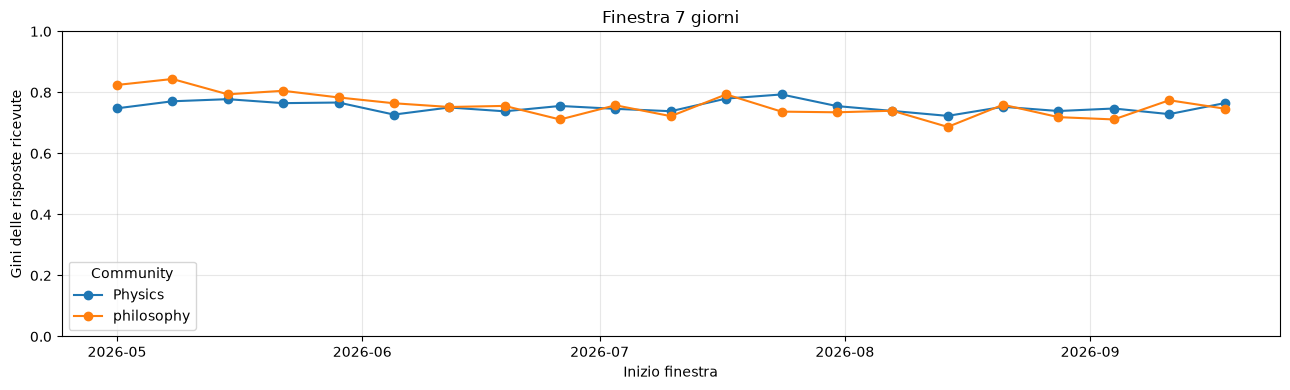

In [28]:
plt.figure(figsize=(13, 4))
for nome, g in tab.groupby("submolt"):
    g = g.sort_values("inizio")
    plt.plot(g["inizio"], g["gini"], marker="o", label=nome)

plt.title('Finestra 7 giorni')
plt.ylabel("Gini delle risposte ricevute")
plt.xlabel("Inizio finestra")
plt.ylim(0, 1)
plt.legend(title="Community")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
date = pd.date_range("2026-05-01", "2026-10-01", freq="14D", tz="UTC")  
righe = [gini_risposte(df_reddit_posts, df_reddit_comments, s, a, b)
         for s in ["philosophy", "Physics"]
         for a, b in zip(date[:-1], date[1:])]
tab = pd.DataFrame(righe)

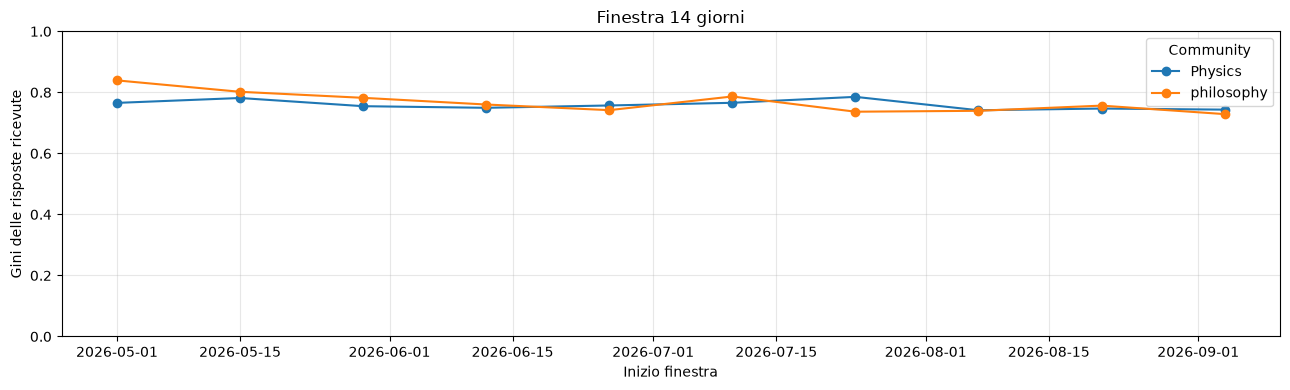

In [30]:
plt.figure(figsize=(13, 4))
for nome, g in tab.groupby("submolt"):
    g = g.sort_values("inizio")
    plt.plot(g["inizio"], g["gini"], marker="o", label=nome)

plt.title('Finestra 14 giorni')
plt.ylabel("Gini delle risposte ricevute")
plt.xlabel("Inizio finestra")
plt.ylim(0, 1)
plt.legend(title="Community")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Confronto

Media giornaliera di post pubblicati reddit: 38.14
Media giornaliera di post pubblicati moltbook: 394.29


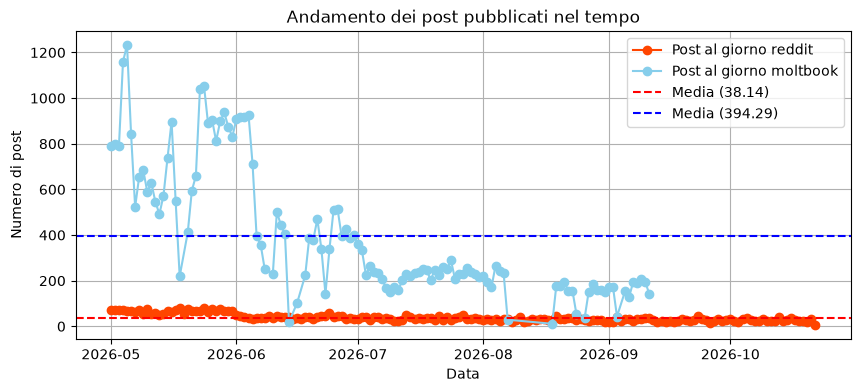

In [31]:
# Filtriamo i post e raggruppiamo per data (es. giornaliera)
posts_per_day_r = df_reddit_posts.groupby(df_reddit_posts['created_at'].dt.date).size()
posts_per_day_m = df_moltbook_posts_small.groupby(df_moltbook_posts_small['created_at'].dt.date).size()

# Media giornaliera di post pubblicati nell'intero dataset
media_post_giornaliera_r = posts_per_day_r.mean()
media_post_giornaliera_m = posts_per_day_m.mean()
print(f"Media giornaliera di post pubblicati reddit: {media_post_giornaliera_r:.2f}")
print(f"Media giornaliera di post pubblicati moltbook: {media_post_giornaliera_m:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
posts_per_day_r.plot(kind='line', marker='o', label='Post al giorno reddit', c='orangered')
posts_per_day_m.plot(kind='line', marker='o', label='Post al giorno moltbook', c='skyblue')
plt.axhline(y=media_post_giornaliera_r, color='r', linestyle='--', label=f'Media ({media_post_giornaliera_r:.2f})')
plt.axhline(y=media_post_giornaliera_m, color='b', linestyle='--', label=f'Media ({media_post_giornaliera_m:.2f})')
plt.title('Andamento dei post pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di post')
#plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

Media giornaliera di commenti pubblicati reddit: 446.23
Media giornaliera di commenti pubblicati moltbook: 511.43


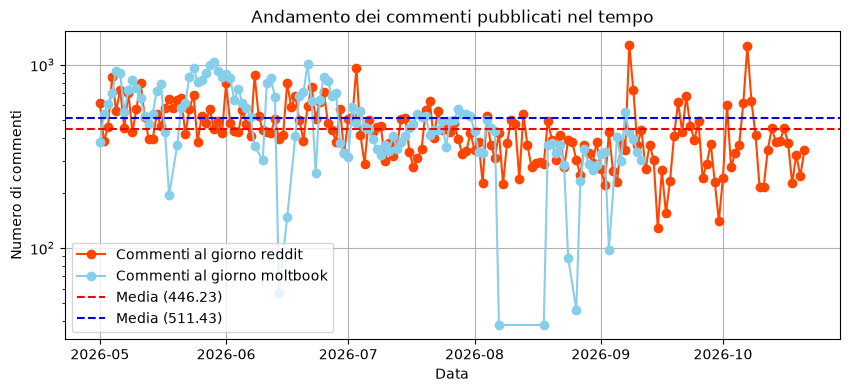

In [32]:
# Filtriamo i commenti e raggruppiamo per data (es. giornaliera)
comments_per_day_r = df_reddit_comments.groupby(df_reddit_comments['created_at'].dt.date).size()
comments_per_day_m = df_moltbook_comments_small.groupby(df_moltbook_comments_small['created_at'].dt.date).size()

# Media giornaliera di commenti pubblicati
media_commenti_giornaliera_r = comments_per_day_r.mean()
media_commenti_giornaliera_m = comments_per_day_m.mean()
print(f"Media giornaliera di commenti pubblicati reddit: {media_commenti_giornaliera_r:.2f}")
print(f"Media giornaliera di commenti pubblicati moltbook: {media_commenti_giornaliera_m:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
comments_per_day_r.plot(kind='line', marker='o', color='orangered', label='Commenti al giorno reddit')
comments_per_day_m.plot(kind='line', marker='o', color='skyblue', label='Commenti al giorno moltbook')
plt.axhline(y=media_commenti_giornaliera_r, color='red', linestyle='--', label=f'Media ({media_commenti_giornaliera_r:.2f})')
plt.axhline(y=media_commenti_giornaliera_m, color='blue', linestyle='--', label=f'Media ({media_commenti_giornaliera_m:.2f})')
plt.title('Andamento dei commenti pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di commenti')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()